In [1]:
import OMPython
import os
import logging
import pandas as pd
import DyMat
import numpy as np
from matplotlib import pyplot as plt

In [ ]:
logging.getLogger("OMPython").setLevel(logging.ERROR)
omc = OMPython.OMCSessionLocal()

# Put your thermopower pacakge paths and resulting directory
omc.sendExpression("loadFile(\"/home/wspark/projects/ThermoPower/ThermoPower/package.mo\")")
omc.sendExpression("loadFile(\"/home/wspark/projects/AmazonRunScripts/ReferenceOM/package.mo\")")
RESULT_DIR = "/home/wspark/projects/OMResults/BaseLoad"

omc.sendExpression(f'cd("{RESULT_DIR}")')

'/home/wspark/projects/OMResults/BaseLoad'

In [ ]:
"Load result .mat"

case_name_PID = "BaseLoad_PID"
mat_PID = DyMat.DyMatFile(RESULT_DIR + "/" + case_name_PID + "_res.mat")

var_map_PID = {
    "T_helium": {"modelicaName": "sens_T_He.T", "nominal": 750},
    "T_steam": {"modelicaName": "sens_T_steam.T", "nominal": 550},
    "P_steam": {"modelicaName": "sens_P_steam.p", "nominal": 14.3},
    "f_grid": {"modelicaName": "sens_frequency.f", "nominal": 60.0},
    "V_condenser": {"modelicaName": "Condenser.condenserShell.ratio_VvVtot", "nominal": 0.85},
    "P_mech": {"modelicaName": "generator.Pm", "nominal": 65.5},
    "P_elec": {"modelicaName": "generator.Pe", "nominal": 65.5},
    "P_reactor": {"modelicaName": "reactorPower_Avg.P", "nominal": 180},
    "P_demand": {"modelicaName": "LoadDemand.y", "nominal": np.nan},
    "T_fuel_hot": {"modelicaName": "Fuel_mixture_Hot.Tmax", "nominal": np.nan},
    "T_fuel_avg": {"modelicaName": "Fuel_mixture_Avg.Tmax", "nominal": np.nan},
    "rho_der_y": {"modelicaName": "RhoDerivative.y", "nominal": 0.0},
    "rho_tot": {"modelicaName": "reactorPower_Avg.rho", "nominal": np.nan},
    "rho_Xe": {"modelicaName": "reactorPower_Avg.rho_Xe", "nominal": np.nan},
    "rho_ext": {"modelicaName": "reactorPower_Avg.rho_ext", "nominal": np.nan},
    "rho_feedback": {"modelicaName": "reactorPower_Avg.rho_feedback", "nominal": np.nan},
    "PID_blower_y": {"modelicaName": "PID_blower.y", "nominal": np.nan},
    "PID_fwpp_y": {"modelicaName": "PID_fwpp.y", "nominal": np.nan},
    "PID_cdpp_y": {"modelicaName": "PID_cdpp.y", "nominal": np.nan},
    "PID_reactivity_y": {"modelicaName": "PID_reactivity.y", "nominal": np.nan},
    "PID_valve_y": {"modelicaName": "PID_valve.y", "nominal": np.nan},
}

time = mat_PID.abscissa("sens_T_He.T", valuesOnly=True)
idx_tot = time > 5000
time = time[idx_tot]-5000

data_PID = {}
for name, info in var_map_PID.items():
    data_PID[name] = {
        "values": mat_PID.data(info["modelicaName"])[idx_tot],
        "nominal": info["nominal"],
    }


case_name_SMC = "BaseLoad_SMC"
mat_SMC = DyMat.DyMatFile(RESULT_DIR + "/" + case_name_SMC + "_res.mat")
var_map_SMC = {
    "T_helium": {"modelicaName": "sens_T_He.T", "nominal": 750},
    "T_steam": {"modelicaName": "sens_T_steam.T", "nominal": 550},
    "P_steam": {"modelicaName": "sens_P_steam.p", "nominal": 14.3},
    "f_grid": {"modelicaName": "sens_frequency.f", "nominal": 60.0},
    "V_condenser": {"modelicaName": "Condenser.condenserShell.ratio_VvVtot", "nominal": 0.85},
    "P_mech": {"modelicaName": "generator.Pm", "nominal": 65.5},
    "P_elec": {"modelicaName": "generator.Pe", "nominal": 65.5},
    "P_reactor": {"modelicaName": "reactorPower_Avg.P", "nominal": 180},
    "P_demand": {"modelicaName": "LoadDemand.y", "nominal": np.nan},
    "T_fuel_hot": {"modelicaName": "Fuel_mixture_Hot.Tmax", "nominal": np.nan},
    "T_fuel_avg": {"modelicaName": "Fuel_mixture_Avg.Tmax", "nominal": np.nan},
    "rho_der_y": {"modelicaName": "RhoDerivative.y", "nominal": 0.0},
    "rho_tot": {"modelicaName": "reactorPower_Avg.rho", "nominal": np.nan},
    "rho_Xe": {"modelicaName": "reactorPower_Avg.rho_Xe", "nominal": np.nan},
    "rho_ext": {"modelicaName": "reactorPower_Avg.rho_ext", "nominal": np.nan},
    "rho_feedback": {"modelicaName": "reactorPower_Avg.rho_feedback", "nominal": np.nan},
    "SMC_blower_y": {"modelicaName": "SMC_blower.y", "nominal": np.nan},
    "SMC_fwpp_y": {"modelicaName": "SMC_fwpp.y", "nominal": np.nan},
    "SMC_cdpp_y": {"modelicaName": "SMC_cdpp.y", "nominal": np.nan},
    "SMC_reactivity_y": {"modelicaName": "SMC_reactivity.y", "nominal": np.nan},
    "SMC_valve_y": {"modelicaName": "SMC_valve.y", "nominal": np.nan},
}

time = mat_SMC.abscissa("sens_T_He.T", valuesOnly=True)
idx_tot = time > 5000
time = time[idx_tot]-5000

data = {}
data["PID"] = {}
data["SMC"] = {}
for name, info in var_map_PID.items():
    data["PID"][name] = {
        "values": mat_PID.data(info["modelicaName"])[idx_tot],
        "nominal": info["nominal"],
    }
for name, info in var_map_SMC.items():
    data["SMC"][name] = {
        "values": mat_SMC.data(info["modelicaName"])[idx_tot],
        "nominal": info["nominal"],
    }

In [ ]:
"Postprocess monthly stats"

days_in_month = [31, 28, 31, 30, 31, 30, 31, 31, 30, 31, 30, 31] 
month_names = ["Jan", "Feb", "Mar", "Apr", "May", "Jun", "Jul", "Aug", "Sep", "Oct", "Nov", "Dec"]
monthly_stats = {}
case_names = ["PID", "SMC"]

for casename in case_names:
    monthly_stats[casename] = {}
    idx = 0
    for month, days in zip(month_names, days_in_month):

        n = days * 24 * 60
        monthly_stats[casename][month] = {}

        for name, info in data[casename].items():

            month_values = info["values"][idx:idx+n]
            nominal = info["nominal"]
            avg = np.mean(month_values)
            monthly_stats[casename][month][name] = {
                "time": time[idx:idx+n],
                "avg": avg,
                "maxRelDev": np.max(np.abs(month_values-nominal)/nominal*100),
                "maxDev": np.max(np.abs(month_values-nominal)),
                "max": np.max(month_values),
                "min": np.min(month_values),
            }

        P_turbine_trim = data[casename]["P_elec"]["values"][idx:idx+n]
        P_demand_trim = data[casename]["P_demand"]["values"][idx:idx+n]
        val_demand = (P_turbine_trim/P_turbine_trim.max()-P_demand_trim)/P_demand_trim*100
        avg = np.mean(val_demand)
        monthly_stats[casename][month]["demand_off"] = {
            "time": time[idx:idx+n],
            "avg": avg,
            "maxRelDev": np.nan,
            "maxDev": np.nan,
            "max": np.max(val_demand),
            "min": np.min(val_demand),
        }

        idx += n

/tmp/ipykernel_897080/2688624039.py:22: RuntimeWarning: divide by zero encountered in divide
  "maxRelDev": np.max(np.abs(month_values-nominal)/nominal*100),


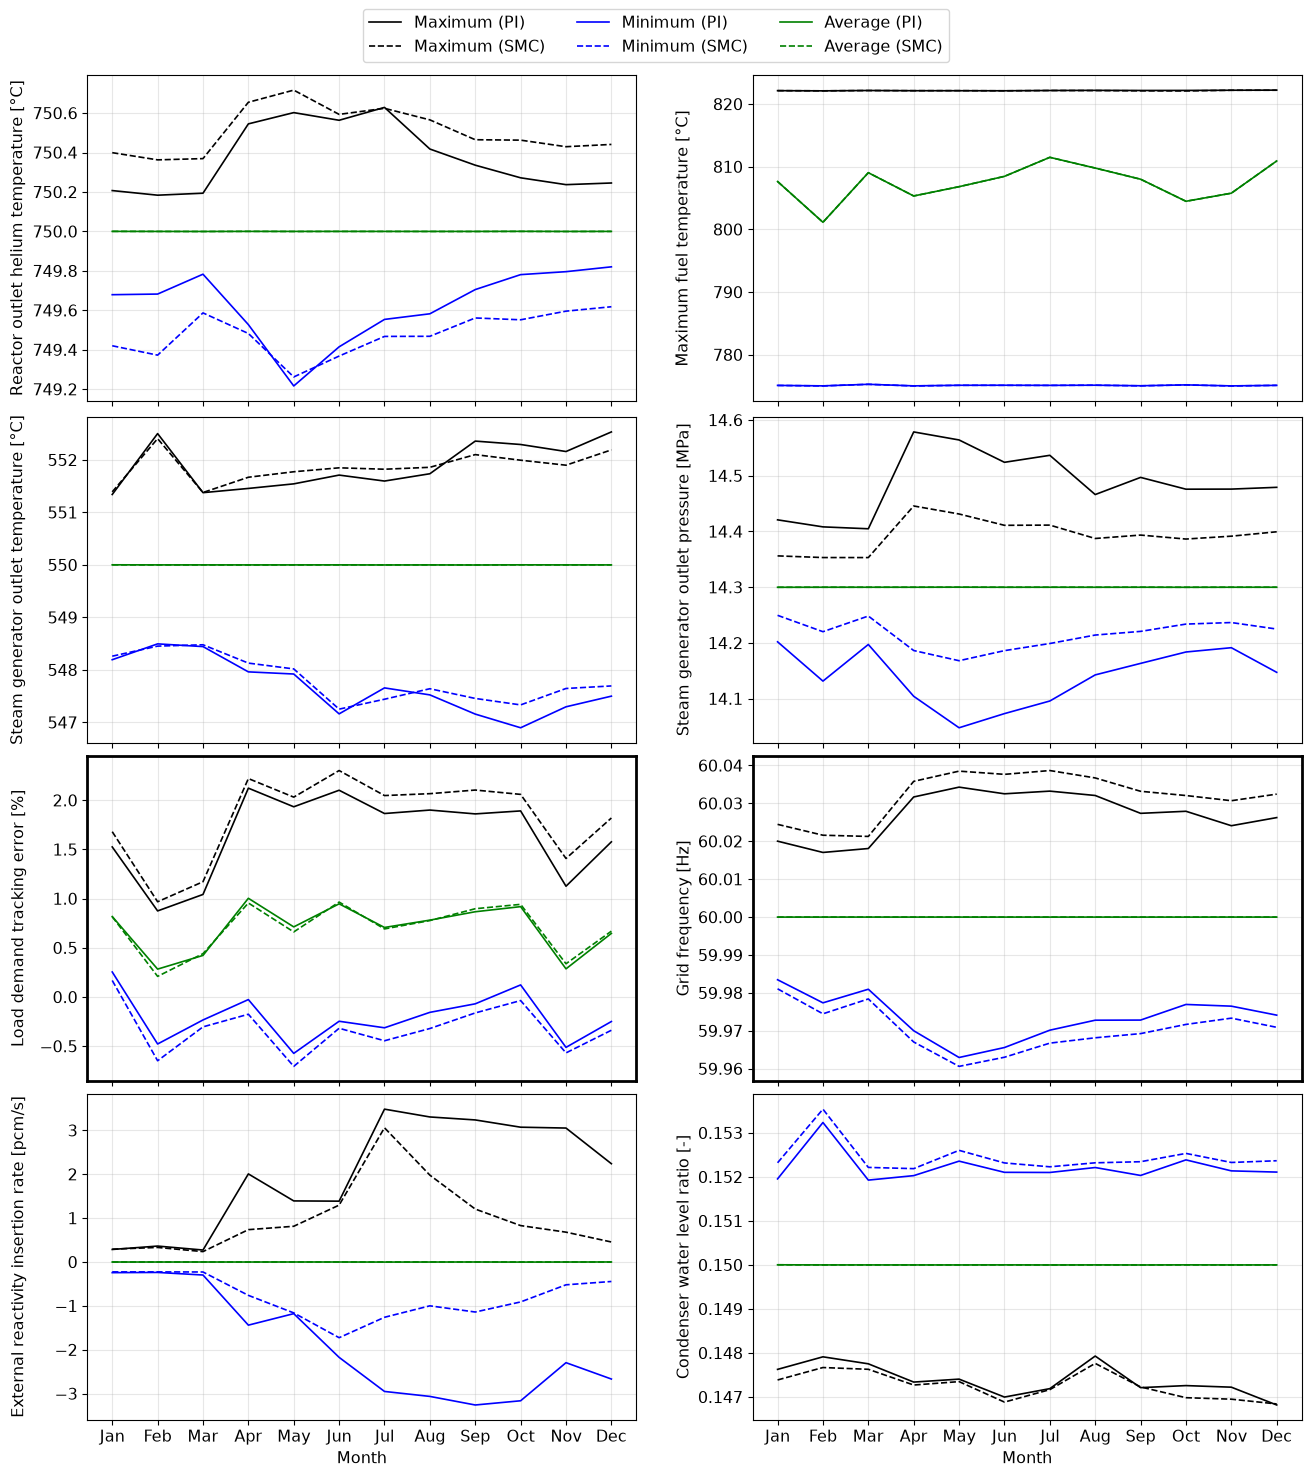

In [ ]:
"Generate figure"

monthly_stats_max = {}
monthly_stats_min = {}
monthly_stats_avg = {}

for casename in case_names:
    monthly_stats_max[casename] = {}
    monthly_stats_min[casename] = {}
    monthly_stats_avg[casename] = {}

    for name, info in data[casename].items():
        monthly_stats_max[casename][name] = np.array([
            monthly_stats[casename][month][name]["max"]
            for month in month_names
        ])
        monthly_stats_min[casename][name] = np.array([
            monthly_stats[casename][month][name]["min"]
            for month in month_names
        ])
        monthly_stats_avg[casename][name] = np.array([
            monthly_stats[casename][month][name]["avg"]
            for month in month_names
        ])

    monthly_stats_max[casename]["demand_off"] = np.array([
        monthly_stats[casename][month]["demand_off"]["max"]
        for month in month_names
        ])
    monthly_stats_min[casename]["demand_off"] = np.array([
        monthly_stats[casename][month]["demand_off"]["min"]
        for month in month_names
        ])
    monthly_stats_avg[casename]["demand_off"] = np.array([
        monthly_stats[casename][month]["demand_off"]["avg"]
        for month in month_names
        ])

figs, axs = plt.subplots(4, 2, figsize=(13,14), sharex=True, constrained_layout=True)
figs.set_constrained_layout_pads(wspace=0.06)
axs = axs.ravel()

plt.rcParams.update({
    "font.size": 11.5,
    "axes.labelsize": 11.5,
    "xtick.labelsize": 11.5,
    "ytick.labelsize": 11.5,
    "legend.fontsize": 11.5,
})

axs[0].plot(month_names, monthly_stats_max["PID"]["T_helium"]-273, label="Maximum (PI)", lw=1.2, color="k")
axs[0].plot(month_names, monthly_stats_min["PID"]["T_helium"]-273, label="Minimum (PI)", lw=1.2, color="b")
axs[0].plot(month_names, monthly_stats_avg["PID"]["T_helium"]-273, label="Average (PI)", lw=1.2, color="g")
axs[0].plot(month_names, monthly_stats_max["SMC"]["T_helium"]-273, label="Maximum (SMC)", lw=1.2, color="k", ls="--")
axs[0].plot(month_names, monthly_stats_min["SMC"]["T_helium"]-273, label="Minimum (SMC)", lw=1.2, color="b", ls="--")
axs[0].plot(month_names, monthly_stats_avg["SMC"]["T_helium"]-273, label="Average (SMC)", lw=1.2, color="g", ls="--")
axs[0].grid(alpha=0.3)
axs[0].set_ylabel("Reactor outlet helium temperature [$\\degree$C]")

axs[1].plot(month_names, monthly_stats_max["PID"]["T_fuel_hot"]-273, label="Maximum (PI)", lw=1.2, color="k")
axs[1].plot(month_names, monthly_stats_min["PID"]["T_fuel_hot"]-273, label="Minimum (PI)", lw=1.2, color="b")
axs[1].plot(month_names, monthly_stats_avg["PID"]["T_fuel_hot"]-273, label="Average (PI)", lw=1.2, color="g")
axs[1].plot(month_names, monthly_stats_max["SMC"]["T_fuel_hot"]-273, label="Maximum (SMC)", lw=1.2, color="k", ls="--")
axs[1].plot(month_names, monthly_stats_min["SMC"]["T_fuel_hot"]-273, label="Minimum (SMC)", lw=1.2, color="b", ls="--")
axs[1].plot(month_names, monthly_stats_avg["SMC"]["T_fuel_hot"]-273, label="Average (SMC)", lw=1.2, color="g", ls="--")
axs[1].grid(alpha=0.3)
axs[1].set_ylabel("Maximum fuel temperature [$\\degree$C]")

axs[2].plot(month_names, monthly_stats_max["PID"]["T_steam"]-273, label="Maximum (PI)", lw=1.2, color="k")
axs[2].plot(month_names, monthly_stats_min["PID"]["T_steam"]-273, label="Minimum (PI)", lw=1.2, color="b")
axs[2].plot(month_names, monthly_stats_avg["PID"]["T_steam"]-273, label="Average (PI)", lw=1.2, color="g")
axs[2].plot(month_names, monthly_stats_max["SMC"]["T_steam"]-273, label="Maximum (SMC)", lw=1.2, color="k", ls="--")
axs[2].plot(month_names, monthly_stats_min["SMC"]["T_steam"]-273, label="Minimum (SMC)", lw=1.2, color="b", ls="--")
axs[2].plot(month_names, monthly_stats_avg["SMC"]["T_steam"]-273, label="Average (SMC)", lw=1.2, color="g", ls="--")
axs[2].grid(alpha=0.3)
axs[2].set_ylabel("Steam generator outlet temperature [$\\degree$C]")

axs[3].plot(month_names, monthly_stats_max["PID"]["P_steam"]/1e6, label="Maximum (PI)", lw=1.2, color="k")
axs[3].plot(month_names, monthly_stats_min["PID"]["P_steam"]/1e6, label="Minimum (PI)", lw=1.2, color="b")
axs[3].plot(month_names, monthly_stats_avg["PID"]["P_steam"]/1e6, label="Average (PI)", lw=1.2, color="g")
axs[3].plot(month_names, monthly_stats_max["SMC"]["P_steam"]/1e6, label="Maximum (SMC)", lw=1.2, color="k", ls="--")
axs[3].plot(month_names, monthly_stats_min["SMC"]["P_steam"]/1e6, label="Minimum (SMC)", lw=1.2, color="b", ls="--")
axs[3].plot(month_names, monthly_stats_avg["SMC"]["P_steam"]/1e6, label="Average (SMC)", lw=1.2, color="g", ls="--")
axs[3].grid(alpha=0.3)
axs[3].set_ylabel("Steam generator outlet pressure [MPa]")

axs[4].plot(month_names, monthly_stats_max["PID"]["demand_off"], label="Maximum (PI)", lw=1.2, color="k")
axs[4].plot(month_names, monthly_stats_min["PID"]["demand_off"], label="Minimum (PI)", lw=1.2, color="b")
axs[4].plot(month_names, monthly_stats_avg["PID"]["demand_off"], label="Average (PI)", lw=1.2, color="g")
axs[4].plot(month_names, monthly_stats_max["SMC"]["demand_off"], label="Maximum (SMC)", lw=1.2, color="k", ls="--")
axs[4].plot(month_names, monthly_stats_min["SMC"]["demand_off"], label="Minimum (SMC)", lw=1.2, color="b", ls="--")
axs[4].plot(month_names, monthly_stats_avg["SMC"]["demand_off"], label="Average (SMC)", lw=1.2, color="g", ls="--")
axs[4].grid(alpha=0.3)
axs[4].set_ylabel("Load demand tracking error [%]")

axs[5].plot(month_names, monthly_stats_max["PID"]["f_grid"], label="Maximum (PI)", lw=1.2, color="k")
axs[5].plot(month_names, monthly_stats_min["PID"]["f_grid"], label="Minimum (PI)", lw=1.2, color="b")
axs[5].plot(month_names, monthly_stats_avg["PID"]["f_grid"], label="Average (PI)", lw=1.2, color="g")
axs[5].plot(month_names, monthly_stats_max["SMC"]["f_grid"], label="Maximum (SMC)", lw=1.2, color="k", ls="--")
axs[5].plot(month_names, monthly_stats_min["SMC"]["f_grid"], label="Minimum (SMC)", lw=1.2, color="b", ls="--")
axs[5].plot(month_names, monthly_stats_avg["SMC"]["f_grid"], label="Average (SMC)", lw=1.2, color="g", ls="--")
axs[5].grid(alpha=0.3)
axs[5].set_ylabel("Grid frequency [Hz]")

axs[6].plot(month_names, monthly_stats_max["PID"]["rho_der_y"]*1e5, label="Maximum (PI)", lw=1.2, color="k")
axs[6].plot(month_names, monthly_stats_min["PID"]["rho_der_y"]*1e5, label="Minimum (PI)", lw=1.2, color="b")
axs[6].plot(month_names, monthly_stats_avg["PID"]["rho_der_y"]*1e5, label="Average (PI)", lw=1.2, color="g")
axs[6].plot(month_names, monthly_stats_max["SMC"]["rho_der_y"]*1e5, label="Maximum (SMC)", lw=1.2, color="k", ls="--")
axs[6].plot(month_names, monthly_stats_min["SMC"]["rho_der_y"]*1e5, label="Minimum (SMC)", lw=1.2, color="b", ls="--")
axs[6].plot(month_names, monthly_stats_avg["SMC"]["rho_der_y"]*1e5, label="Average (SMC)", lw=1.2, color="g", ls="--")
axs[6].grid(alpha=0.3)
axs[6].set_ylabel("External reactivity insertion rate [pcm/s]")
axs[6].set_xlabel("Month")

axs[7].plot(month_names, 1-monthly_stats_max["PID"]["V_condenser"], label="Maximum (PI)", lw=1.2, color="k")
axs[7].plot(month_names, 1-monthly_stats_min["PID"]["V_condenser"], label="Minimum (PI)", lw=1.2, color="b")
axs[7].plot(month_names, 1-monthly_stats_avg["PID"]["V_condenser"], label="Average (PI)", lw=1.2, color="g")
axs[7].plot(month_names, 1-monthly_stats_max["SMC"]["V_condenser"], label="Maximum (SMC)", lw=1.2, color="k", ls="--")
axs[7].plot(month_names, 1-monthly_stats_min["SMC"]["V_condenser"], label="Minimum (SMC)", lw=1.2, color="b", ls="--")
axs[7].plot(month_names, 1-monthly_stats_avg["SMC"]["V_condenser"], label="Average (SMC)", lw=1.2, color="g", ls="--")
axs[7].grid(alpha=0.3)
axs[7].set_ylabel("Condenser water level ratio [-]")
axs[7].set_xlabel("Month")


handles, labels = axs[0].get_legend_handles_labels()
order = [0, 3, 1, 4, 2, 5]
handles = [handles[i] for i in order]
labels  = [labels[i] for i in order]
figs.legend(
    handles,
    labels,
    loc="upper center",
    bbox_to_anchor=(0.5, 1.05),
    ncol=3,
    frameon=True,
)

for spine in axs[4].spines.values():
    spine.set_linewidth(2.0)
for spine in axs[5].spines.values():
    spine.set_linewidth(2.0)

figs.align_ylabels(axs[::2])
figs.align_ylabels(axs[1::2])
# figs.savefig("aggregated_result.pdf", bbox_inches="tight")